<a href="https://colab.research.google.com/github/shivamkumar359/03-rd-SEM--ASSIGNMENTS/blob/main/PDS/W13/Q2/ASSIGNMENT_2.1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Sorted edges file created.

MINIMUM SPANNING TREE
A -- B : 1
A -- C : 1
C -- D : 2
E -- F : 2
D -- E : 3

Rejected edges (cycle formation / redundant paths):
B -- C : 2
B -- D : 3
C -- E : 4
D -- F : 5
A -- F : 6

Total MST Weight: 9


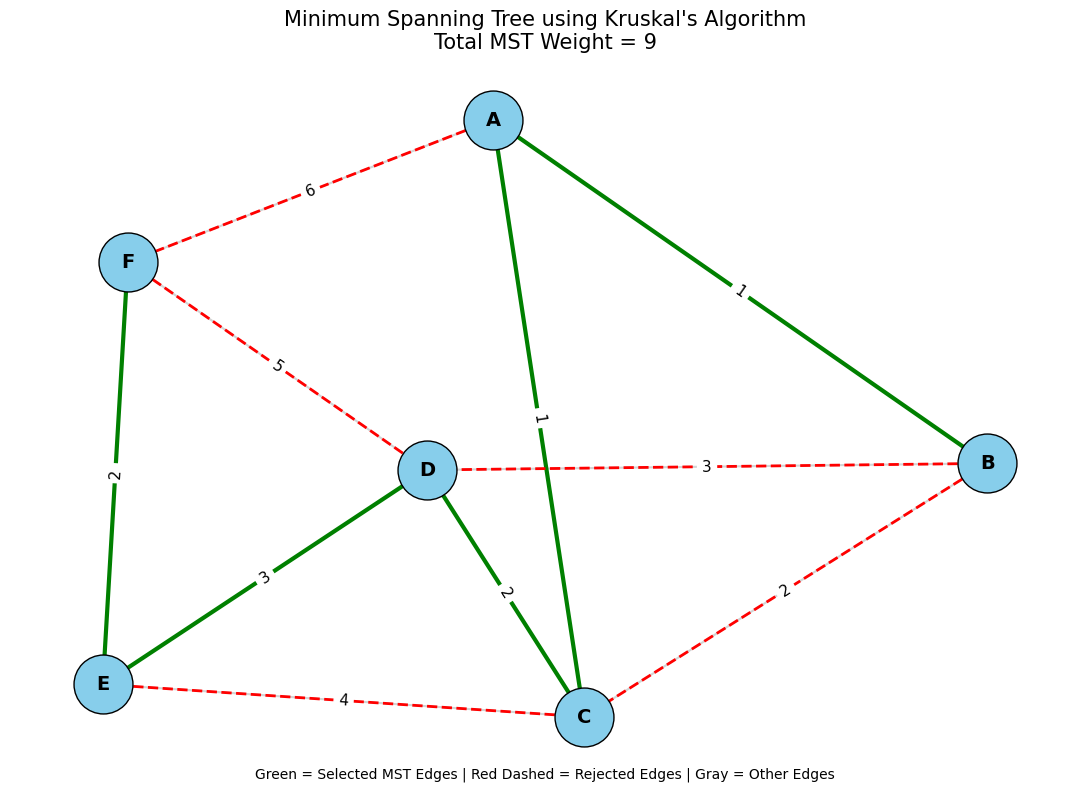


2. Spanning tree PNG created.

3. Topological sequence file created.

DFS STACK PUSH ORDER
F -> D -> B -> E -> C -> A

FINAL TOPOLOGICAL ORDER:
A -> C -> E -> B -> D -> F

TASK 2 COMPLETED SUCCESSFULLY

GENERATED FILES:

1. sorted_edges.txt
2. spanning_tree.png
3. topological_sequence.txt

4. Task_2_Submission.zip

MST Total Weight: 9
MST Selected Edges: 5
Topological Vertices: 6


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# ============================================================
# TASK 2: TRACE SPANNING TREE WEIGHTS AND TOPOLOGICAL ORDERING
# Algorithms:
# 1. Kruskal's Minimum Spanning Tree
# 2. DFS-Based Topological Sorting
# ============================================================

import os
import zipfile
import matplotlib.pyplot as plt
import networkx as nx

from google.colab import files

# ------------------------------------------------------------
# 1. CREATE OUTPUT DIRECTORY
# ------------------------------------------------------------

OUTPUT_DIR = "Task_2_Spanning_Tree"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. WEIGHTED UNDIRECTED GRAPH
# ------------------------------------------------------------

vertices = ['A', 'B', 'C', 'D', 'E', 'F']

# Format: (Source, Destination, Weight)
edges = [
    ('A', 'B', 1),
    ('A', 'C', 1),
    ('B', 'C', 2),
    ('B', 'D', 3),
    ('C', 'D', 2),
    ('C', 'E', 4),
    ('D', 'E', 3),
    ('D', 'F', 5),
    ('E', 'F', 2),
    ('A', 'F', 6)
]

# Sort edges by ascending weight
sorted_edges = sorted(edges, key=lambda x: (x[2], x[0], x[1]))

# ------------------------------------------------------------
# 3. SAVE SORTED EDGES
# ------------------------------------------------------------

sorted_file = os.path.join(OUTPUT_DIR, "sorted_edges.txt")

with open(sorted_file, "w") as f:

    f.write("TASK 2: SORTED GRAPH EDGES\n")
    f.write("Algorithm: Kruskal's Minimum Spanning Tree\n\n")

    f.write("Edges arranged in ascending order of weight:\n\n")

    for u, v, w in sorted_edges:
        f.write(f"{u} -- {v} : Weight = {w}\n")

print("1. Sorted edges file created.")

# ------------------------------------------------------------
# 4. UNION-FIND DATA STRUCTURE
# ------------------------------------------------------------

parent = {v: v for v in vertices}
rank = {v: 0 for v in vertices}

def find(vertex):

    if parent[vertex] != vertex:
        parent[vertex] = find(parent[vertex])

    return parent[vertex]


def union(u, v):

    root_u = find(u)
    root_v = find(v)

    if root_u == root_v:
        return False

    if rank[root_u] < rank[root_v]:
        parent[root_u] = root_v

    elif rank[root_u] > rank[root_v]:
        parent[root_v] = root_u

    else:
        parent[root_v] = root_u
        rank[root_u] += 1

    return True

# ------------------------------------------------------------
# 5. KRUSKAL'S MINIMUM SPANNING TREE
# ------------------------------------------------------------

mst_edges = []
rejected_edges = []
total_weight = 0

for u, v, w in sorted_edges:

    if len(mst_edges) < len(vertices) - 1 and union(u, v):
        mst_edges.append((u, v, w))
        total_weight += w
    else:
        rejected_edges.append((u, v, w))

# ------------------------------------------------------------
# 6. DISPLAY MST RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 50)
print("MINIMUM SPANNING TREE")
print("=" * 50)

for u, v, w in mst_edges:
    print(f"{u} -- {v} : {w}")

print("\nRejected edges (cycle formation / redundant paths):")

for u, v, w in rejected_edges:
    print(f"{u} -- {v} : {w}")

print("\nTotal MST Weight:", total_weight)

assert len(mst_edges) == len(vertices) - 1
assert len(mst_edges) + len(rejected_edges) == len(edges)

# ------------------------------------------------------------
# 7. DRAW SPANNING TREE DIAGRAM
# ------------------------------------------------------------

G = nx.Graph()

G.add_nodes_from(vertices)
G.add_weighted_edges_from(edges)

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(11, 8))

# Draw all original graph edges
nx.draw_networkx_edges(
    G,
    pos,
    edgelist=edges,
    edge_color='lightgray',
    width=1.5
)

# Draw selected MST edges
nx.draw_networkx_edges(
    G,
    pos,
    edgelist=[(u, v) for u, v, w in mst_edges],
    edge_color='green',
    width=3
)

# Draw rejected edges in red
nx.draw_networkx_edges(
    G,
    pos,
    edgelist=[(u, v) for u, v, w in rejected_edges],
    edge_color='red',
    style='dashed',
    width=2
)

nx.draw_networkx_nodes(
    G,
    pos,
    node_color='skyblue',
    node_size=1800,
    edgecolors='black'
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=14,
    font_weight='bold'
)

edge_labels = {
    (u, v): w for u, v, w in edges
}

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=11
)

plt.title(
    f"Minimum Spanning Tree using Kruskal's Algorithm\n"
    f"Total MST Weight = {total_weight}",
    fontsize=15
)

plt.figtext(
    0.5, 0.02,
    "Green = Selected MST Edges | Red Dashed = Rejected Edges | Gray = Other Edges",
    ha="center",
    fontsize=10
)

plt.axis('off')
plt.tight_layout()

png_file = os.path.join(
    OUTPUT_DIR, "spanning_tree.png"
)

plt.savefig(png_file, dpi=300, bbox_inches='tight')
plt.show()

print("\n2. Spanning tree PNG created.")

# ------------------------------------------------------------
# 8. DIRECTED DEPENDENCY GRAPH
# ------------------------------------------------------------

directed_edges = [
    ('A', 'C'),
    ('A', 'B'),
    ('B', 'D'),
    ('C', 'D'),
    ('C', 'E'),
    ('D', 'F'),
    ('E', 'F')
]

DG = nx.DiGraph()

DG.add_nodes_from(vertices)
DG.add_edges_from(directed_edges)

# Validate that the dependency graph is a DAG
assert nx.is_directed_acyclic_graph(DG), \
    "Dependency graph contains a cycle!"

# ------------------------------------------------------------
# 9. DFS-BASED TOPOLOGICAL SORTING
# ------------------------------------------------------------

visited = set()
recursion_stack = set()
push_order = []

def dfs(vertex):

    visited.add(vertex)
    recursion_stack.add(vertex)

    for neighbor in sorted(DG.neighbors(vertex)):

        if neighbor not in visited:
            dfs(neighbor)

        elif neighbor in recursion_stack:
            raise ValueError("Cycle detected in dependency graph!")

    recursion_stack.remove(vertex)

    # Push vertex after exploring all dependencies
    push_order.append(vertex)


for vertex in sorted(vertices):

    if vertex not in visited:
        dfs(vertex)

# Pop stack to obtain topological ordering
topological_order = push_order[::-1]

# ------------------------------------------------------------
# 10. VALIDATE TOPOLOGICAL ORDER
# ------------------------------------------------------------

position = {
    vertex: index
    for index, vertex in enumerate(topological_order)
}

for u, v in directed_edges:

    assert position[u] < position[v], (
        f"Invalid ordering: {u} must appear before {v}"
    )

# ------------------------------------------------------------
# 11. SAVE TOPOLOGICAL SEQUENCE
# ------------------------------------------------------------

topological_file = os.path.join(
    OUTPUT_DIR, "topological_sequence.txt"
)

with open(topological_file, "w") as f:

    f.write("TASK 2: TOPOLOGICAL SORTING\n")
    f.write("Algorithm: Depth First Search (DFS)\n\n")

    f.write("Directed Dependency Edges:\n")

    for u, v in directed_edges:
        f.write(f"{u} -> {v}\n")

    f.write("\nDFS STACK PUSH ORDER:\n")
    f.write(" -> ".join(push_order))

    f.write("\n\nFINAL TOPOLOGICAL ORDER:\n")
    f.write(" -> ".join(topological_order))

    f.write("\n\nVERTEX POSITIONS:\n")

    for index, vertex in enumerate(topological_order):
        f.write(f"{vertex}: Position {index + 1}\n")

    f.write("\nVALIDATION:\n")
    f.write("All dependency constraints satisfied.\n")
    f.write("No directed cycles detected.\n")

print("\n3. Topological sequence file created.")

# ------------------------------------------------------------
# 12. DISPLAY TOPOLOGICAL RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 50)
print("DFS STACK PUSH ORDER")
print("=" * 50)

print(" -> ".join(push_order))

print("\nFINAL TOPOLOGICAL ORDER:")

print(" -> ".join(topological_order))

# ------------------------------------------------------------
# 13. CREATE SUBMISSION ZIP
# ------------------------------------------------------------

zip_filename = "Task_2_Submission.zip"

with zipfile.ZipFile(
    zip_filename,
    'w',
    zipfile.ZIP_DEFLATED
) as zipf:

    zipf.write(
        sorted_file,
        "sorted_edges.txt"
    )

    zipf.write(
        png_file,
        "spanning_tree.png"
    )

    zipf.write(
        topological_file,
        "topological_sequence.txt"
    )

# ------------------------------------------------------------
# 14. FINAL VALIDATION
# ------------------------------------------------------------

assert os.path.exists(sorted_file)
assert os.path.exists(png_file)
assert os.path.exists(topological_file)
assert os.path.exists(zip_filename)

print("\n" + "=" * 55)
print("TASK 2 COMPLETED SUCCESSFULLY")
print("=" * 55)

print("""
GENERATED FILES:

1. sorted_edges.txt
2. spanning_tree.png
3. topological_sequence.txt

4. Task_2_Submission.zip
""")

print("MST Total Weight:", total_weight)
print("MST Selected Edges:", len(mst_edges))
print("Topological Vertices:", len(topological_order))

# Download ZIP
files.download(zip_filename)